<a href="https://colab.research.google.com/github/jpcardenas2026-ship-it/mi-dashboard-ventas/blob/main/Taller_Graficos_Publicacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller · De los datos a un dashboard publicado

**Programación — ADMI 1301**

Trabajarás con las **2.000 ventas de una cadena de papelerías en 2025**. En este taller vas a:

1. **Graficar** (6 ejercicios con `groupby`, `crosstab` y `pivot_table`).
2. **Organizar** tus gráficos en una sola figura con `subplots`: tu *dashboard*.
3. **Embellecerlo con prompts**: le pides a Gemini que reescriba el código de tu figura y pegas su respuesta aquí.
4. **Elegir tu versión favorita**, escribir tus conclusiones y **publicar tu notebook en GitHub**.

Las instrucciones completas están en la guía en Word. Aquí encuentras lo esencial de cada ejercicio y una **verificación** (`assert`) para saber si vas bien.

**Escriba los nombres de los integrantes aca.**
______________________________________________________________________  
 1.   
 2.   
 3.    
    


## 0. Preparación
Ejecuta la celda y sube el archivo **`ventas_papelerias_2025.csv`**.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

subidos = files.upload()   # selecciona ventas_papelerias_2025.csv

df = pd.read_csv("ventas_papelerias_2025.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month        # 1 = enero ... 12 = diciembre
df.head()

Saving ventas_papelerias_2025.csv to ventas_papelerias_2025 (1).csv


,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


**Conoce tus datos** antes de graficar: cuántas filas hay, qué columnas, qué valores tiene cada categoría.

In [ ]:
print(df.shape)
df.info()
for col in ["ciudad", "canal", "segmento", "categoria", "metodo_pago"]:
    print(col, "->", sorted(df[col].unique()))

(2000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_venta         2000 non-null   object        
 1   fecha            2000 non-null   datetime64[ns]
 2   ciudad           2000 non-null   object        
 3   canal            2000 non-null   object        
 4   segmento         2000 non-null   object        
 5   vendedor         2000 non-null   object        
 6   producto         2000 non-null   object        
 7   categoria        2000 non-null   object        
 8   metodo_pago      2000 non-null   object        
 9   cantidad         2000 non-null   int64         
 10  precio_unitario  2000 non-null   int64         
 11  descuento        2000 non-null   float64       
 12  total            2000 non-null   int64         
 13  mes              2000 non-null   int32         
dtypes: datetime64[ns](1), float64

---
# Parte A · Seis gráficos
En cada ejercicio: **(1)** prepara una tabla con `groupby`, `crosstab` o `pivot_table`, **(2)** guárdala en la variable indicada, **(3)** grafícala. Ponle **título** a cada gráfico.

### Ejercicio 1 · Top 5 de productos *(barras horizontales)*
**Contexto.** La gerente de compras debe decidir en qué productos concentrar el inventario del próximo año.

**Tarea.** Calcula los ingresos (`total`) por `producto`, quédate con los **5 mayores** y grafícalos en barras horizontales. Guarda la tabla en **`top_productos`**.

*Herramientas:* `groupby`, `sum`, `sort_values`, `head`, `.plot.barh()`

In [ ]:
# Ejercicio 1

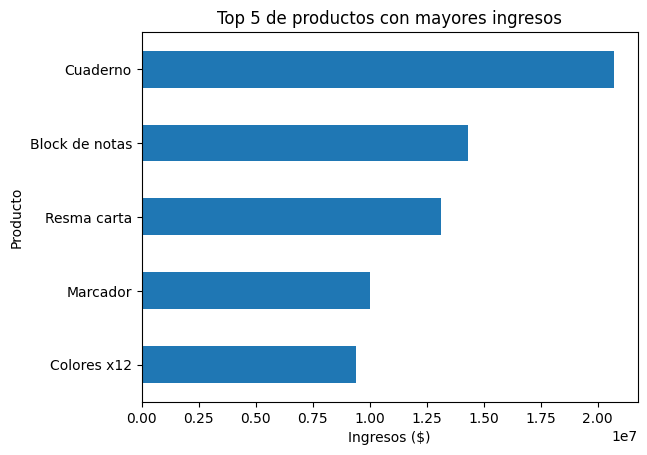

Ejercicio 1 correcto ✔


In [ ]:
# ✅ Verificación

top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)

top_productos.sort_values().plot.barh(
    title="Top 5 de productos con mayores ingresos",
    xlabel="Ingresos ($)",
    ylabel="Producto"
)

plt.show()


assert len(top_productos) == 5, "Debe haber exactamente 5 productos"
assert top_productos.index[0] == "Cuaderno", "El producto con más ingresos no coincide: revisa el ordenamiento"
assert abs(top_productos.iloc[0] - 20712345) < 1, "Revisa que estés sumando la columna total"
print("Ejercicio 1 correcto ✔")



### Ejercicio 2 · Ingresos mes a mes: Bogotá vs Medellín *(líneas)*
**Contexto.** La dirección regional quiere comparar la evolución de sus dos ciudades principales durante el año.

**Tarea.** **Selecciona** solo las ventas de Bogotá y Medellín (`isin`). Con una **tabla dinámica** pon los meses en las filas, las ciudades en las columnas y la suma de `total` como valores. Guárdala en **`ing_mes_ciudad`** y grafícala como líneas con marcadores.

*Herramientas:* filtrado con `isin`, `pivot_table`, `.plot.line(marker="o")`

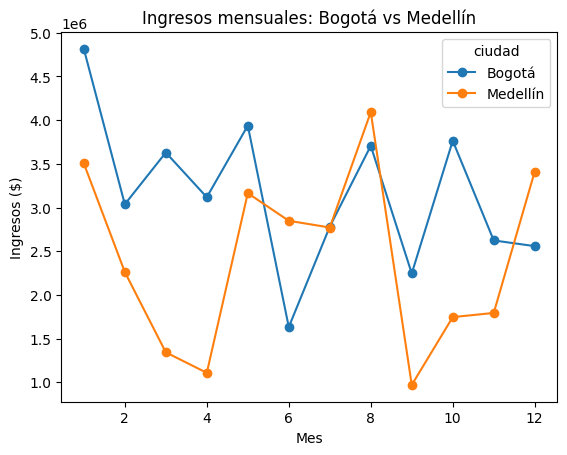

In [ ]:
# Ejercicio 2

df_dos_ciudades = df[df["ciudad"].isin(["Bogotá", "Medellín"])]

ing_mes_ciudad = df_dos_ciudades.pivot_table(
    values="total",
    index="mes",
    columns="ciudad",
    aggfunc="sum"
)

ing_mes_ciudad.plot.line(
    marker="o",
    title="Ingresos mensuales: Bogotá vs Medellín",
    xlabel="Mes",
    ylabel="Ingresos ($)"
)

plt.show()


In [ ]:
# ✅ Verificación
assert ing_mes_ciudad.shape == (12, 2), f"Se esperaba una tabla de 12 meses x 2 ciudades, tienes {ing_mes_ciudad.shape}"
assert set(ing_mes_ciudad.columns) == {"Bogotá", "Medellín"}, "Las columnas deben ser las dos ciudades"
assert abs(ing_mes_ciudad["Bogotá"].sum() - 37847614) < 1, "El total de Bogotá no coincide"
print("Ejercicio 2 correcto ✔")

Ejercicio 2 correcto ✔


### Ejercicio 3 · ¿Por qué canal se vende más? *(gráfico de pie)*
**Contexto.** La empresa evalúa si invierte más en su tienda online o en la atención telefónica.

**Tarea.** Calcula los ingresos totales por `canal`, guárdalos en **`ing_canal`** y grafica la participación de cada canal con un gráfico de pie que muestre los **porcentajes con un decimal**.

*Herramientas:* `groupby`, `.plot.pie(autopct=...)`

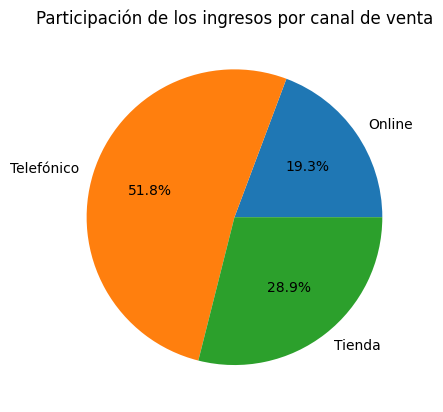

In [ ]:
# Ejercicio 3

ing_canal = df.groupby("canal")["total"].sum()

ing_canal.plot.pie(
    autopct="%1.1f%%",
    title="Participación de los ingresos por canal de venta",
    ylabel=""
)

plt.show()


In [ ]:
# ✅ Verificación
assert abs(ing_canal.sum() - 118668012) < 1, "La suma de los canales debe ser el ingreso total"
assert abs(ing_canal["Telefónico"] / ing_canal.sum() - 0.520) < 0.01, "La participación del canal Telefónico no coincide"
print("Ejercicio 3 correcto ✔")

Ejercicio 3 correcto ✔


### Ejercicio 4 · ¿Cada segmento compra lo mismo? *(barras apiladas)*
**Contexto.** El área comercial sospecha que los clientes corporativos compran productos distintos a los minoristas.

**Tarea.** Con `pd.crosstab` cuenta las ventas por `segmento` (filas) y `categoria` (columnas), **normalizadas por fila** y expresadas en **porcentaje** (de 0 a 100). Guarda la tabla en **`tabla_seg_cat`** y grafícala en barras **apiladas**.

*Herramientas:* `pd.crosstab(..., normalize="index")`, `.plot.bar(stacked=True)`

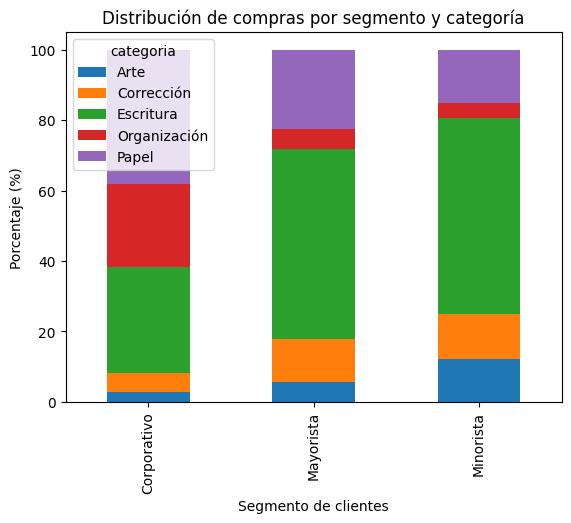

In [ ]:
# Ejercicio 4

tabla_seg_cat = pd.crosstab(
    df["segmento"],
    df["categoria"],
    normalize="index"
) * 100

tabla_seg_cat.plot.bar(
    stacked=True,
    title="Distribución de compras por segmento y categoría",
    xlabel="Segmento de clientes",
    ylabel="Porcentaje (%)"
)

plt.show()


In [ ]:
# ✅ Verificación
assert tabla_seg_cat.shape == (3, 5), f"Se esperaba 3 segmentos x 5 categorías, tienes {tabla_seg_cat.shape}"
assert (abs(tabla_seg_cat.sum(axis=1) - 100) < 0.01).all(), "Cada fila debe sumar 100 (usa normalize y multiplica por 100)"
print("Ejercicio 4 correcto ✔")

Ejercicio 4 correcto ✔


### Ejercicio 5 · Productividad de los vendedores *(dispersión)*
**Contexto.** Recursos humanos revisa qué vendedores concretan más ventas y cuáles venden tickets más altos.

**Tarea.** Con `groupby` por `vendedor` y `ciudad`, calcula para cada vendedor el **número de ventas** (`n_ventas`) y el **valor promedio de sus ventas** (`ticket_prom`). Guarda la tabla en **`vend`** (con índice normal: usa `reset_index()`). Haz una dispersión (`n_ventas` en X, `ticket_prom` en Y) con un **color por ciudad** y leyenda.

*Herramientas:* `groupby().agg(nombre=("columna", "función"))`, `reset_index`, `plt.scatter` dentro de un `for`

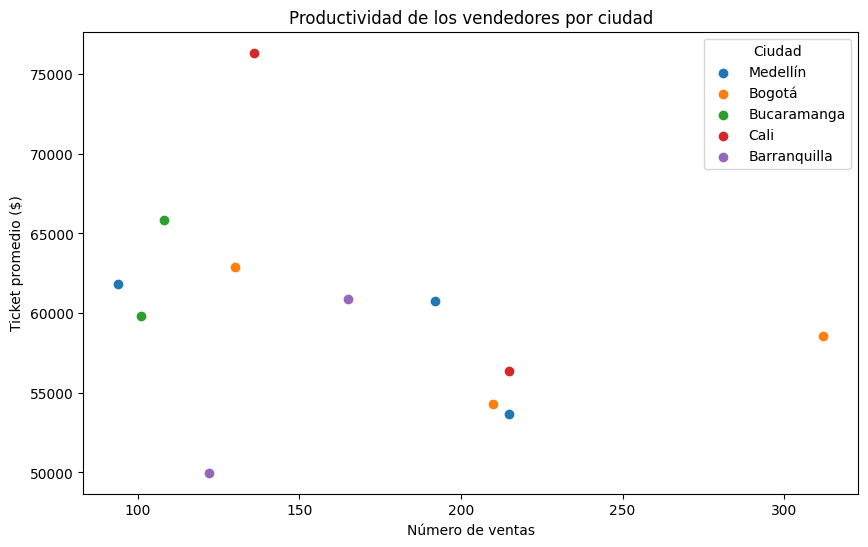

In [ ]:
# Ejercicio 5

vend = df.groupby(["vendedor", "ciudad"]).agg(
    n_ventas=("id_venta", "count"),
    ticket_prom=("total", "mean")
).reset_index()

plt.figure(figsize=(10, 6))

for ciudad in vend["ciudad"].unique():
    datos = vend[vend["ciudad"] == ciudad]

    plt.scatter(
        datos["n_ventas"],
        datos["ticket_prom"],
        label=ciudad
    )

plt.title("Productividad de los vendedores por ciudad")
plt.xlabel("Número de ventas")
plt.ylabel("Ticket promedio ($)")
plt.legend(title="Ciudad")

plt.show()


In [ ]:
# ✅ Verificación
assert vend.shape[0] == 12, f"Debe haber una fila por vendedor (12), tienes {vend.shape[0]}"
assert {"vendedor", "ciudad", "n_ventas", "ticket_prom"} <= set(vend.columns), "Faltan columnas: vendedor, ciudad, n_ventas, ticket_prom"
assert vend["n_ventas"].sum() == 2000, "La suma de n_ventas debe ser 2000"
print("Ejercicio 5 correcto ✔")

Ejercicio 5 correcto ✔


### Ejercicio 6 · ¿Qué tan grandes son las ventas de cada segmento? *(diagrama de cajas)*
**Contexto.** Para planear el segundo semestre, finanzas quiere ver cómo se distribuye el valor de las ventas por tipo de cliente.

**Tarea.** **Selecciona** solo las ventas del **segundo semestre** (`mes` de 7 a 12) y guárdalas en **`sem2`**. Haz un diagrama de cajas del `total` por `segmento`, **sin mostrar los valores atípicos** (`showfliers=False`).

*Herramientas:* filtro con `>=`, `.boxplot(column=..., by=...)`

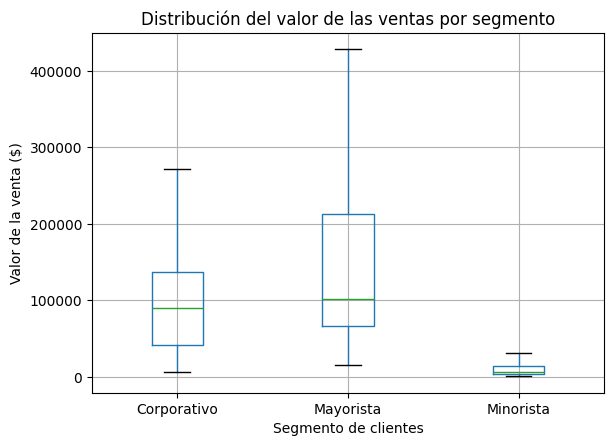

In [ ]:
# Ejercicio 6

sem2 = df[df["mes"] >= 7]

sem2.boxplot(
    column="total",
    by="segmento",
    showfliers=False
)

plt.title("Distribución del valor de las ventas por segmento")
plt.suptitle("")
plt.xlabel("Segmento de clientes")
plt.ylabel("Valor de la venta ($)")

plt.show()


In [ ]:
# ✅ Verificación
assert len(sem2) == 1050, f"El segundo semestre debe tener 1050 ventas, tienes {len(sem2)}"
print("Ejercicio 6 correcto ✔")

Ejercicio 6 correcto ✔


---
# Parte B · Todo en una sola figura (`subplots`)
### Ejercicio 7 · Organiza tus 6 gráficos en una cuadrícula de 2 × 3
**Contexto.** La gerente quiere ver todo en **una sola imagen** para presentarla en la junta.

**Tarea.** Crea una figura con `fig, axs = plt.subplots(2, 3, figsize=(18, 10))` y dibuja cada gráfico en su posición pasando **`ax=axs[fila, columna]`**. Agrega un título general con `fig.suptitle(...)` y termina con `plt.tight_layout()`.

**Importante:** escribe el código en la celda que empieza con `%%writefile figura_base.py` (así el programa guarda tu código en un archivo, que usarás en la Parte C). Luego ejecuta la celda siguiente (`%run -i figura_base.py`) para ver la figura.

*Pistas:* `plot.barh(ax=axs[0, 0])` · `plot.pie(...)` también acepta `ax` · para el boxplot: `boxplot(column=..., by=..., ax=...)` · para la dispersión: `axs[1, 1].scatter(...)`

In [ ]:

%%writefile figura_base.py

# Ejercicio 7: Dashboard de ventas 2025

fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# Grafico 1: Top 5 productos
top_productos.sort_values().plot.barh(
    ax=axs[0, 0],
    title="Top 5 productos",
    xlabel="Ingresos ($)",
    ylabel="Producto"
)

# Grafico 2: Ingresos por ciudad
ing_mes_ciudad.plot.line(
    ax=axs[0, 1],
    marker="o",
    title="Ingresos mensuales: Bogotá vs Medellín",
    xlabel="Mes",
    ylabel="Ingresos ($)"
)

# Grafico 3: Ingresos por canal
ing_canal.plot.pie(
    ax=axs[0, 2],
    autopct="%1.1f%%",
    title="Participación de ingresos por canal",
    ylabel=""
)

# Grafico 4: Segmentos y categorias
tabla_seg_cat.plot.bar(
    ax=axs[1, 0],
    stacked=True,
    title="Compras por segmento y categoría",
    xlabel="Segmento",
    ylabel="Porcentaje (%)"
)

# Grafico 5: Productividad de vendedores
for ciudad in vend["ciudad"].unique():
    datos = vend[vend["ciudad"] == ciudad]

    axs[1, 1].scatter(
        datos["n_ventas"],
        datos["ticket_prom"],
        label=ciudad
    )

axs[1, 1].set_title("Productividad de vendedores")
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio ($)")
axs[1, 1].legend(title="Ciudad")

# Grafico 6: Ventas por segmento
sem2.boxplot(
    column="total",
    by="segmento",
    ax=axs[1, 2],
    showfliers=False
)

axs[1, 2].set_title("Ventas por segmento (segundo semestre)")
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Valor de venta ($)")

# Titulo general
fig.suptitle(
    "Dashboard de ventas de la cadena de papelerías · 2025",
    fontsize=18
)

plt.tight_layout()
plt.show()


Overwriting figura_base.py


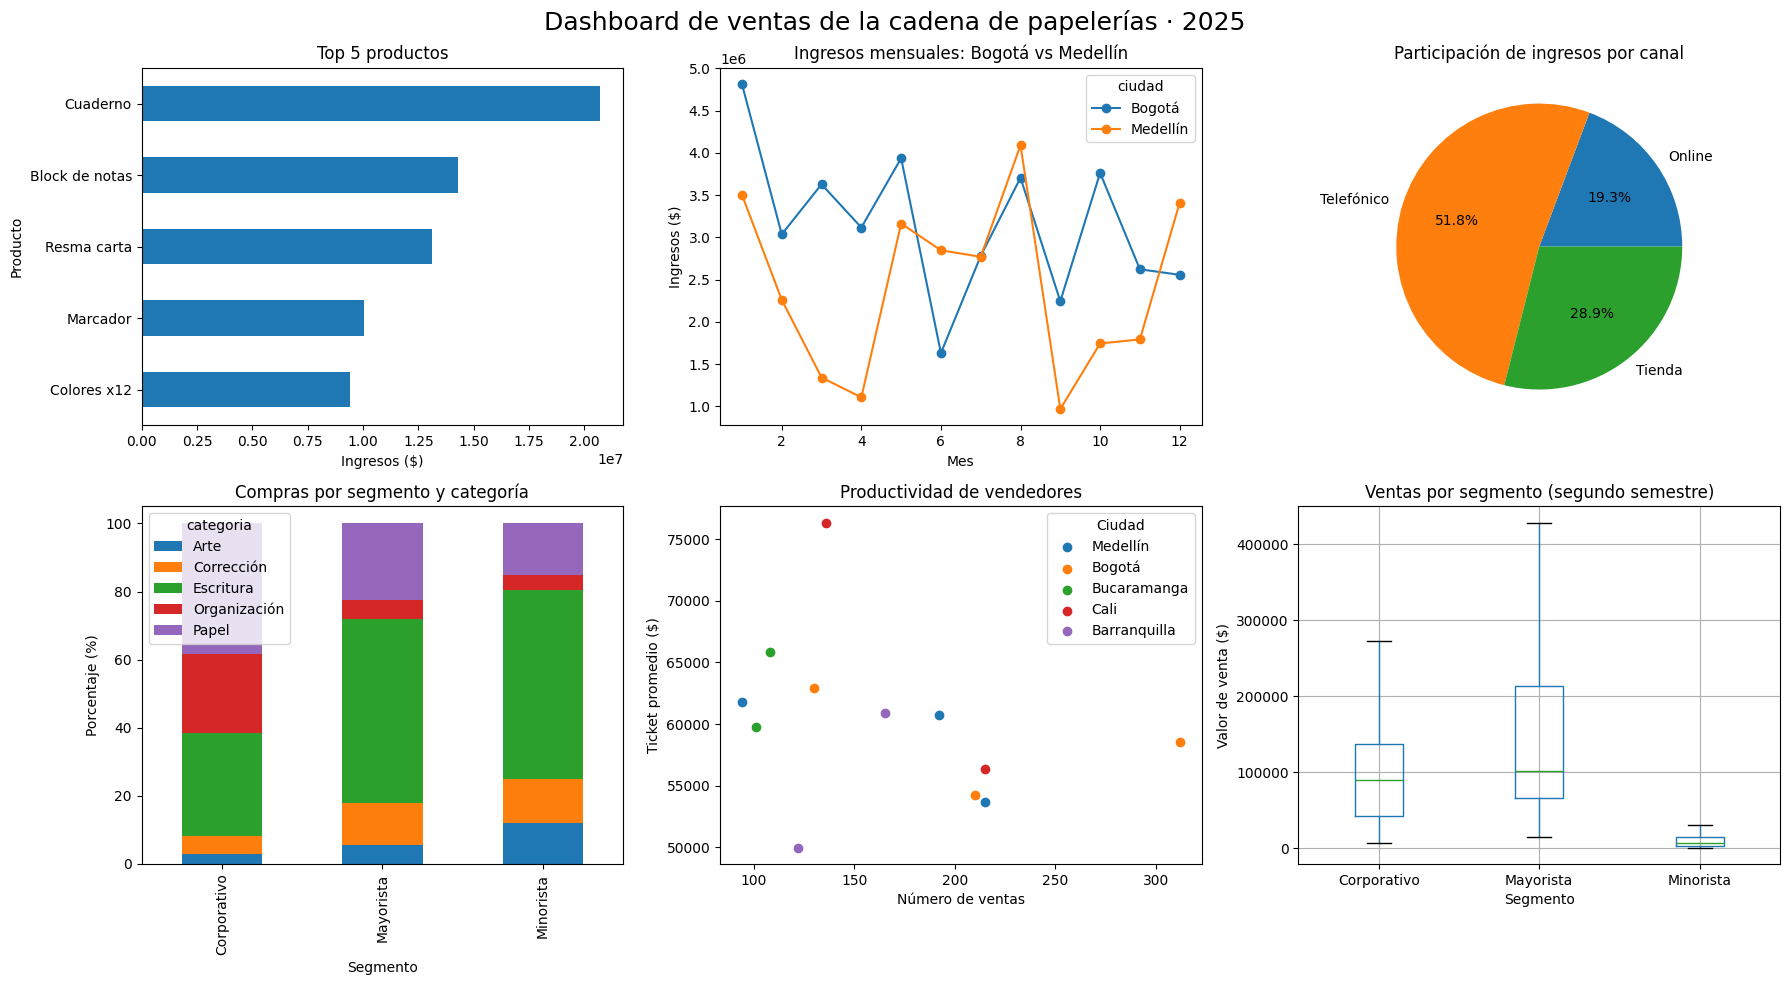

<Figure size 640x480 with 0 Axes>

In [ ]:
%run -i figura_base.py

In [ ]:
# ✅ Verificación
assert len(fig.axes) >= 6, f"La figura debe tener 6 gráficos, tiene {len(fig.axes)}"
print("Ejercicio 7 correcto ✔")

Ejercicio 7 correcto ✔


---
# Parte C · Hazla ver bonita con prompts
Ahora **tú escribes el prompt** y se lo envías a Gemini (en [gemini.google.com](https://gemini.google.com) o la IA que prefieras). Gemini **reescribe el código** de tu figura para que se vea profesional, casi como un dashboard. Tú pegas ese código en el notebook y lo ejecutas.

**El ciclo, cada vez:**
1. Ejecuta la celda de herramientas: te muestra **tu código actual** y las **reglas técnicas**.
2. Escribe tu prompt (Ejercicios 8 y 9).
3. En el chat de la IA pega, en este orden: **tu prompt + tu código + las reglas**.
4. Copia **solo el código** de la respuesta (botón *copiar* del bloque) y pégalo en la celda `%%writefile figura_v1.py`. **No incluyas las líneas con \`\`\`** ni el texto que la IA escriba fuera del bloque.
5. Ejecuta la celda y luego `mostrar("v1")` para ver la figura.

### Herramientas *(ya están hechas)*
Ejecuta la celda: define la función `mostrar(nombre)` (dibuja la versión guardada en `figura_<nombre>.py`) e imprime lo que debes copiar a la IA.

In [ ]:
REGLAS_FIGURA = """

Reglas técnicas obligatorias:
- Usa solo pandas y matplotlib (y numpy si lo necesitas). No instales otras librerías.
- Los datos ya están cargados en el DataFrame `df` (columnas: id_venta, fecha, ciudad, canal, segmento, vendedor,
  producto, categoria, metodo_pago, cantidad, precio_unitario, descuento, total, mes). No cargues archivos.
- Conserva los MISMOS 6 gráficos y los mismos datos del código actual; cambia solo la presentación.
- La figura debe quedar en una variable llamada `fig` (2 filas x 3 columnas).
- NO uses plt.show() ni guardes archivos.
- Entrega solo UN bloque de código Python completo.
"""


def mostrar(nombre):
    """Dibuja la versión guardada en figura_<nombre>.py."""
    plt.close("all")
    codigo = open(f"figura_{nombre}.py", encoding="utf-8").read().replace("plt.show()", "")
    exec(codigo, globals())
    display(fig)
    plt.close(fig)


print("=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===")
print(open("figura_base.py", encoding="utf-8").read())
print("\n=== 2) COPIA ESTAS REGLAS al final de tu prompt ===")
print(REGLAS_FIGURA)

=== 1) COPIA ESTE CÓDIGO (tu figura actual) ===

# Ejercicio 7: Dashboard de ventas 2025

fig, axs = plt.subplots(2, 3, figsize=(18, 10))

# Grafico 1: Top 5 productos
top_productos.sort_values().plot.barh(
    ax=axs[0, 0],
    title="Top 5 productos",
    xlabel="Ingresos ($)",
    ylabel="Producto"
)

# Grafico 2: Ingresos por ciudad
ing_mes_ciudad.plot.line(
    ax=axs[0, 1],
    marker="o",
    title="Ingresos mensuales: Bogotá vs Medellín",
    xlabel="Mes",
    ylabel="Ingresos ($)"
)

# Grafico 3: Ingresos por canal
ing_canal.plot.pie(
    ax=axs[0, 2],
    autopct="%1.1f%%",
    title="Participación de ingresos por canal",
    ylabel=""
)

# Grafico 4: Segmentos y categorias
tabla_seg_cat.plot.bar(
    ax=axs[1, 0],
    stacked=True,
    title="Compras por segmento y categoría",
    xlabel="Segmento",
    ylabel="Porcentaje (%)"
)

# Grafico 5: Productividad de vendedores
for ciudad in vend["ciudad"].unique():
    datos = vend[vend["ciudad"] == ciudad]

    axs[1, 1].scatter(


### Ejercicio 8 · Tu primer prompt de estilo
Completa las secciones de `prompt_v1`. Sé **específico**: "usa una paleta de azules y naranja" funciona mejor que "hazlo bonito".

- **PÚBLICO Y OBJETIVO:** quién verá la figura y para qué.
- **PALETA Y TIPOGRAFÍA:** colores (por ciudad, por producto…), fondo, tamaños de letra.
- **TÍTULOS:** que cada gráfico tenga un título que diga la **conclusión** (por ejemplo, "Bogotá lidera las ventas"), no solo el nombre.
- **EJES Y NÚMEROS:** formatos con separador de miles o "$ 12 M", etiquetas de ejes claras.
- **LIMPIEZA VISUAL:** quitar bordes y marcos innecesarios, cuadrícula suave, valores sobre las barras.

Ejecuta la primera celda para imprimir tu prompt y cópialo a la IA (con tu código y las reglas). Luego pega el código que te devuelva en la segunda celda y muestra la figura con la tercera.

In [ ]:
prompt_v1 = """
PÚBLICO Y OBJETIVO: El dashboard está dirigido a la gerencia de una cadena
de papelerías y será presentado en una junta directiva.
Debe transmitir profesionalismo, claridad y facilitar
la interpretación de los resultados de ventas de 2025

PALETA Y TIPOGRAFÍA: Utiliza una paleta corporativa elegante con azul oscuro,
azul claro, blanco y detalles en naranja.
Asigna colores consistentes a cada ciudad.
Utiliza una fuente sans-serif moderna, títulos en negrita
y un fondo claro.

TÍTULOS: Cada gráfico debe tener un título descriptivo que
facilite entender la información presentada.
Mantén los seis gráficos originales.

EJES Y NÚMEROS: Utiliza separadores de miles para los valores monetarios.
Identifica claramente los ejes y expresa los ingresos
en pesos colombianos (COP).
Mantén los porcentajes con un decimal.

LIMPIEZA VISUAL: Elimina bordes innecesarios, utiliza cuadrículas suaves,
mejora los espacios entre gráficos y organiza las leyendas.
Evita saturar el dashboard con elementos decorativos.
Mantén una distribución equilibrada y legible.
"""

print(prompt_v1)    # cópialo en la IA, junto con tu código y las reglas


PÚBLICO Y OBJETIVO: El dashboard está dirigido a la gerencia de una cadena
de papelerías y será presentado en una junta directiva.
Debe transmitir profesionalismo, claridad y facilitar
la interpretación de los resultados de ventas de 2025

PALETA Y TIPOGRAFÍA: Utiliza una paleta corporativa elegante con azul oscuro,
azul claro, blanco y detalles en naranja.
Asigna colores consistentes a cada ciudad.
Utiliza una fuente sans-serif moderna, títulos en negrita
y un fondo claro.

TÍTULOS: Cada gráfico debe tener un título descriptivo que
facilite entender la información presentada.
Mantén los seis gráficos originales.

EJES Y NÚMEROS: Utiliza separadores de miles para los valores monetarios.
Identifica claramente los ejes y expresa los ingresos
en pesos colombianos (COP).
Mantén los porcentajes con un decimal.

LIMPIEZA VISUAL: Elimina bordes innecesarios, utiliza cuadrículas suaves,
mejora los espacios entre gráficos y organiza las leyendas.
Evita saturar el dashboard con elementos decora

In [ ]:

%%writefile figura_v1.py

from matplotlib.ticker import FuncFormatter

# Paleta corporativa
colores_ciudad = {
    "Bogotá": "#17365D",
    "Medellín": "#F28C28",
    "Cali": "#2E8B57",
    "Barranquilla": "#E5B52F",
    "Bucaramanga": "#8064A2"
}

colores_canal = ["#17365D", "#F28C28", "#8BA6C9"]

fig, axs = plt.subplots(2, 3, figsize=(20, 12))
fig.patch.set_facecolor("#F4F6FA")

for ax in axs.flat:
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.18, linestyle="--")
    ax.set_axisbelow(True)

# 1. Top 5 productos
top_productos.sort_values().plot.barh(
    ax=axs[0, 0],
    color="#17365D",
    edgecolor="none"
)
axs[0, 0].set_title(
    "Cuaderno lidera los ingresos por producto",
    fontsize=12, fontweight="bold", loc="left"
)
axs[0, 0].set_xlabel("Ingresos (COP)")
axs[0, 0].set_ylabel("")
axs[0, 0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, p: f"${x/1e6:.1f} M")
)
axs[0, 0].grid(axis="x", alpha=0.18)
axs[0, 0].grid(axis="y", visible=False)

# 2. Ingresos Bogotá vs Medellín
ing_mes_ciudad.plot.line(
    ax=axs[0, 1],
    marker="o",
    linewidth=2.5,
    markersize=5,
    color=[
        colores_ciudad["Bogotá"],
        colores_ciudad["Medellín"]
    ]
)
axs[0, 1].set_title(
    "Evolución mensual: Bogotá y Medellín",
    fontsize=12, fontweight="bold", loc="left"
)
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos (COP)")
axs[0, 1].yaxis.set_major_formatter(
    FuncFormatter(lambda x, p: f"${x/1e6:.1f} M")
)
axs[0, 1].legend(frameon=False)
axs[0, 1].grid(axis="y", alpha=0.2)

# 3. Ingresos por canal
ing_canal.plot.pie(
    ax=axs[0, 2],
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    colors=colores_canal,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 9}
)
axs[0, 2].set_title(
    "El canal telefónico concentra la facturación",
    fontsize=12, fontweight="bold", loc="left"
)
axs[0, 2].set_ylabel("")

# 4. Segmentos y categorías
tabla_seg_cat.plot.bar(
    ax=axs[1, 0],
    stacked=True,
    color=["#17365D", "#F28C28", "#2E8B57", "#8064A2", "#8BA6C9"],
    width=0.65,
    edgecolor="white"
)
axs[1, 0].set_title(
    "Composición de compras por segmento",
    fontsize=12, fontweight="bold", loc="left"
)
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Participación (%)")
axs[1, 0].legend(
    title="Categoría",
    frameon=False,
    fontsize=8
)
axs[1, 0].grid(axis="y", alpha=0.18)

# 5. Productividad de vendedores
for ciudad in vend["ciudad"].unique():
    datos = vend[vend["ciudad"] == ciudad]
    axs[1, 1].scatter(
        datos["n_ventas"],
        datos["ticket_prom"],
        label=ciudad,
        color=colores_ciudad[ciudad],
        s=75,
        alpha=0.85,
        edgecolors="white",
        linewidths=0.7
    )

axs[1, 1].set_title(
    "Productividad comercial por ciudad",
    fontsize=12, fontweight="bold", loc="left"
)
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio (COP)")
axs[1, 1].yaxis.set_major_formatter(
    FuncFormatter(lambda x, p: f"${x/1000:.0f} mil")
)
axs[1, 1].legend(
    title="Ciudad",
    frameon=False,
    fontsize=8
)

# 6. Distribución de ventas del segundo semestre
sem2.boxplot(
    column="total",
    by="segmento",
    ax=axs[1, 2],
    showfliers=False,
    patch_artist=True,
    boxprops={"facecolor": "#8BA6C9", "alpha": 0.8},
    medianprops={"color": "#F28C28", "linewidth": 2},
    whiskerprops={"color": "#17365D"},
    capprops={"color": "#17365D"}
)
axs[1, 2].set_title(
    "Distribución de ventas del segundo semestre",
    fontsize=12, fontweight="bold", loc="left"
)
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Valor de venta (COP)")
axs[1, 2].yaxis.set_major_formatter(
    FuncFormatter(lambda x, p: f"${x/1000:.0f} mil")
)
fig.suptitle(
    "DASHBOARD COMERCIAL | CADENA DE PAPELERÍAS | 2025",
    fontsize=19,
    fontweight="bold",
    color="#17365D",
    y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.96])


Overwriting figura_v1.py


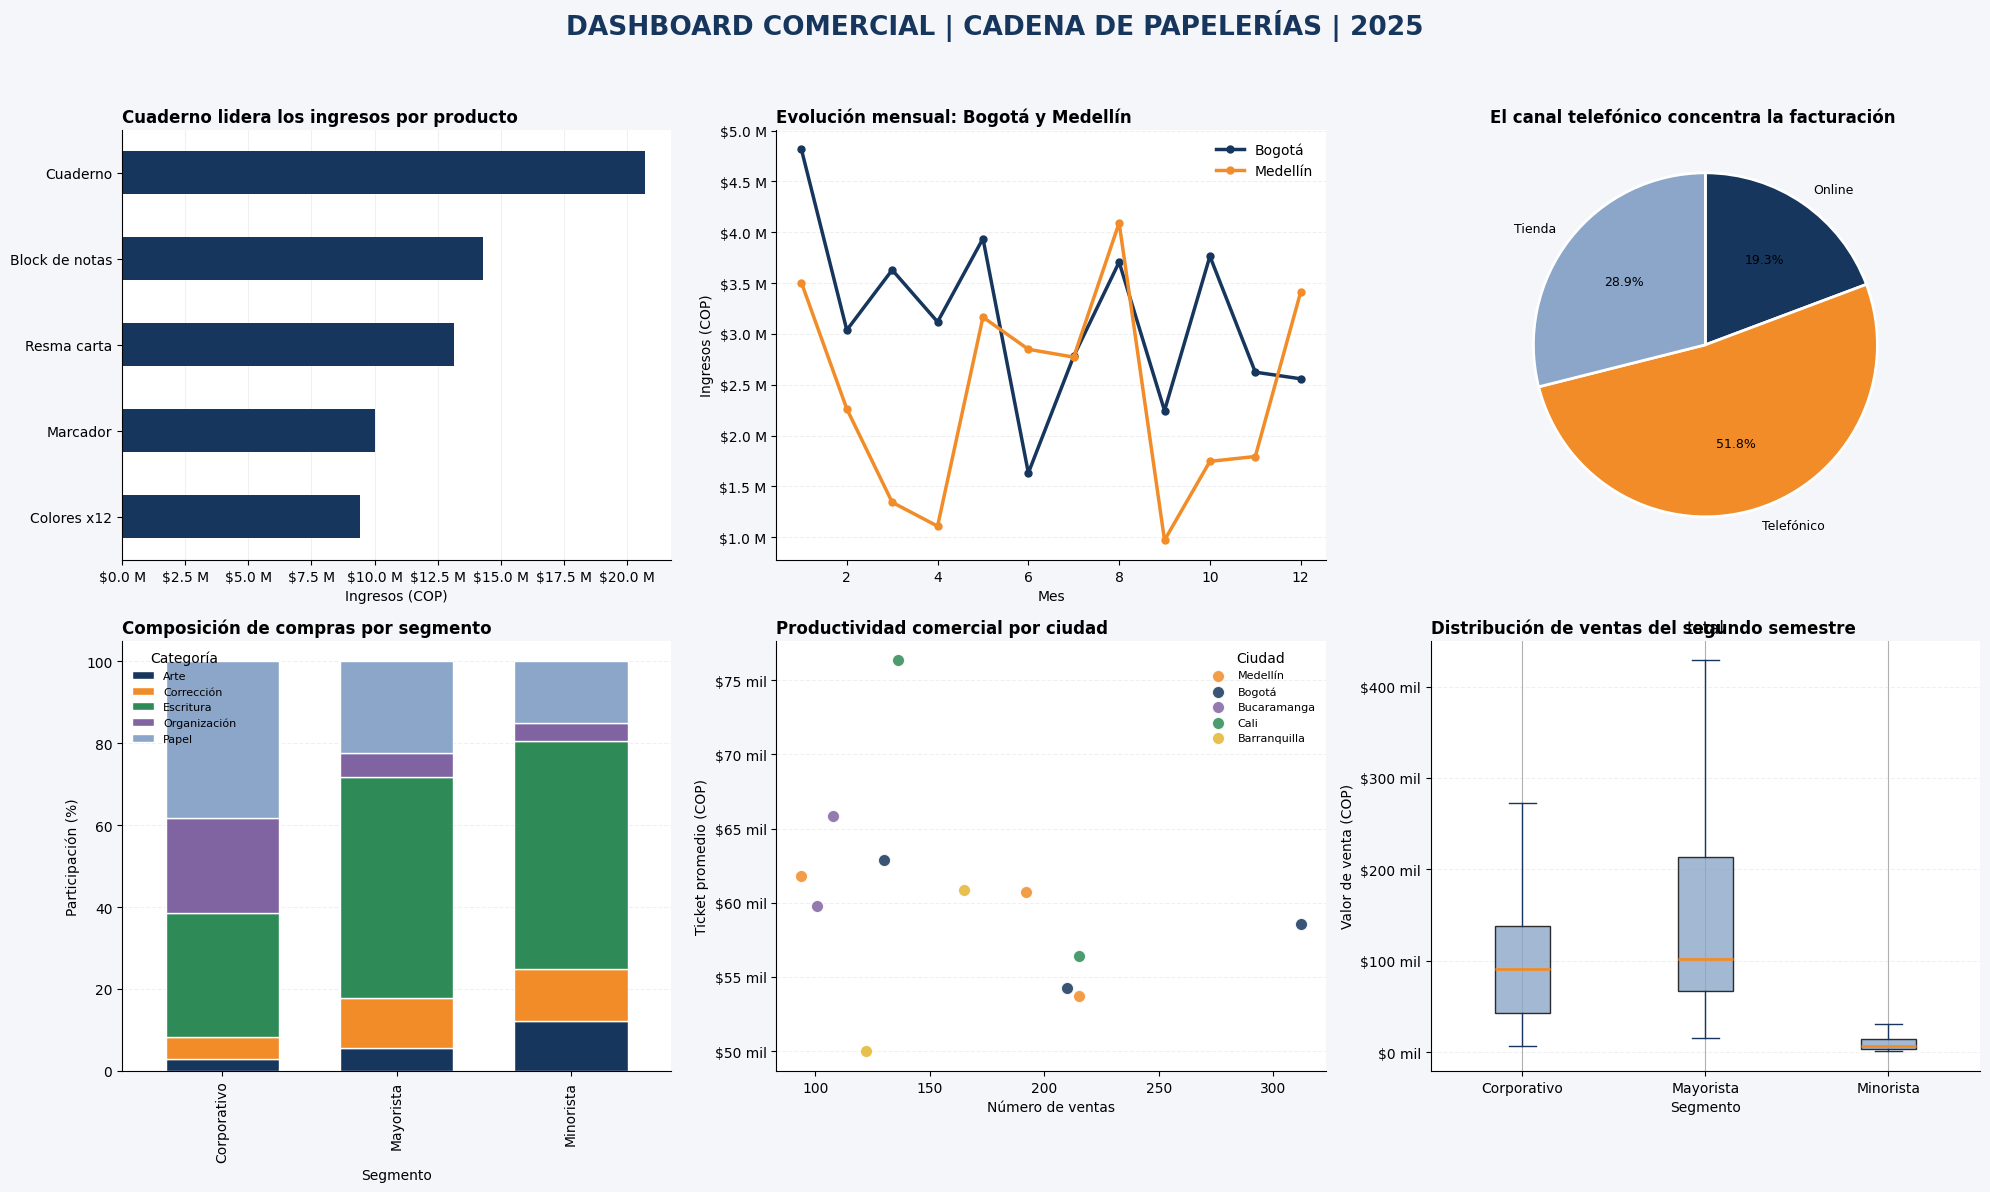

In [ ]:
mostrar("v1")

### Ejercicio 9 · Itera: mejora tu prompt
Mira la figura que obtuviste: ¿qué no te gusta? Agrega una sección **AJUSTES** con **al menos dos cambios concretos** (otra paleta, letras más grandes, una dona en lugar del pie, anotar el valor máximo del gráfico de líneas…). Es la **iteración de prompts** que vimos en clase. Repite el ciclo: copia `prompt_v2` a la IA (con tu código base y las reglas), pega el código en `figura_v2.py` y muestra la figura.

In [ ]:

prompt_v2 = """
AJUSTES SOBRE LA VERSIÓN 1:

1. Cambia el gráfico circular de ingresos por canal
por un gráfico de dona, conservando los porcentajes
originales y destacando el 51.8% del canal telefónico.

2. Reubica la leyenda del gráfico de categorías para
que no tape las barras apiladas.

3. Mejora la leyenda del gráfico de dispersión,
utilizando una distribución compacta y ordenada.

4. Corrige la superposición del título automático
del diagrama de cajas con su título principal.

5. Aumenta ligeramente los espacios entre los seis
paneles para mejorar la lectura.

CONSERVACIÓN:
Mantén exactamente los mismos seis gráficos,
los mismos datos, las mismas tablas y los mismos
cálculos de la versión original.
Conserva la cuadrícula de dos filas y tres columnas,
la variable fig y los nombres de las variables.
No inventes cifras ni modifiques los resultados.

ESTILO:
Mantén la identidad corporativa azul marino,
blanco y naranja. Conserva una apariencia limpia,
elegante y profesional.
"""
print(prompt_v2)



AJUSTES SOBRE LA VERSIÓN 1:

1. Cambia el gráfico circular de ingresos por canal
por un gráfico de dona, conservando los porcentajes
originales y destacando el 51.8% del canal telefónico.

2. Reubica la leyenda del gráfico de categorías para
que no tape las barras apiladas.

3. Mejora la leyenda del gráfico de dispersión,
utilizando una distribución compacta y ordenada.

4. Corrige la superposición del título automático
del diagrama de cajas con su título principal.

5. Aumenta ligeramente los espacios entre los seis
paneles para mejorar la lectura.

CONSERVACIÓN:
Mantén exactamente los mismos seis gráficos,
los mismos datos, las mismas tablas y los mismos
cálculos de la versión original.
Conserva la cuadrícula de dos filas y tres columnas,
la variable fig y los nombres de las variables.
No inventes cifras ni modifiques los resultados.

ESTILO:
Mantén la identidad corporativa azul marino,
blanco y naranja. Conserva una apariencia limpia,
elegante y profesional.



In [ ]:

%%writefile figura_v2.py

from matplotlib.ticker import FuncFormatter

# Paleta corporativa
colores_ciudad = {
    "Bogotá": "#17365D",
    "Medellín": "#F28C28",
    "Cali": "#2E8B57",
    "Barranquilla": "#E5B52F",
    "Bucaramanga": "#8064A2"
}

fig, axs = plt.subplots(2, 3, figsize=(21, 13))
fig.patch.set_facecolor("#F4F6FA")

for ax in axs.flat:
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.15, linestyle="--")
    ax.set_axisbelow(True)

# 1. Top 5 productos
top_productos.sort_values().plot.barh(
    ax=axs[0, 0],
    color="#17365D",
    edgecolor="none"
)

axs[0, 0].set_title(
    "Cuaderno lidera los ingresos",
    fontsize=13, fontweight="bold", loc="left"
)
axs[0, 0].set_xlabel("Ingresos (COP)")
axs[0, 0].set_ylabel("")
axs[0, 0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, p: f"${x/1e6:.1f} M")
)
axs[0, 0].grid(axis="x", alpha=0.15)
axs[0, 0].grid(axis="y", visible=False)

# 2. Ingresos por ciudad
ing_mes_ciudad.plot.line(
    ax=axs[0, 1],
    marker="o",
    linewidth=2.5,
    markersize=6,
    color=["#17365D", "#F28C28"]
)

axs[0, 1].set_title(
    "Evolución mensual de ingresos",
    fontsize=13, fontweight="bold", loc="left"
)
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos (COP)")
axs[0, 1].yaxis.set_major_formatter(
    FuncFormatter(lambda x, p: f"${x/1e6:.1f} M")
)
axs[0, 1].legend(
    title="Ciudad",
    frameon=False,
    loc="upper right"
)

# 3. Dona: ingresos por canal
ing_canal.plot.pie(
    ax=axs[0, 2],
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    colors=["#17365D", "#F28C28", "#8BA6C9"],
    wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2},
    pctdistance=0.78,
    textprops={"fontsize": 9}
)

axs[0, 2].set_title(
    "Participación de ingresos por canal",
    fontsize=13, fontweight="bold", loc="left"
)
axs[0, 2].set_ylabel("")

# 4. Compras por segmento y categoría
tabla_seg_cat.plot.bar(
    ax=axs[1, 0],
    stacked=True,
    color=["#17365D", "#F28C28", "#2E8B57", "#8064A2", "#8BA6C9"],
    edgecolor="white",
    width=0.65
)

axs[1, 0].set_title(
    "Composición de compras por segmento",
    fontsize=13, fontweight="bold", loc="left"
)
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Participación (%)")
axs[1, 0].legend(
    title="Categoría",
    frameon=False,
    fontsize=8,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.19),
    ncol=3
)

# 5. Productividad de vendedores
for ciudad in vend["ciudad"].unique():
    datos = vend[vend["ciudad"] == ciudad]

    axs[1, 1].scatter(
        datos["n_ventas"],
        datos["ticket_prom"],
        label=ciudad,
        color=colores_ciudad[ciudad],
        s=85,
        alpha=0.85,
        edgecolors="white",
        linewidths=0.8
    )

axs[1, 1].set_title(
    "Productividad comercial por ciudad",
    fontsize=13, fontweight="bold", loc="left"
)
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio (COP)")
axs[1, 1].yaxis.set_major_formatter(
    FuncFormatter(lambda x, p: f"${x/1000:.0f} mil")
)
axs[1, 1].legend(
    title="Ciudad",
    frameon=False,
    fontsize=8,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.19),
    ncol=3
)

# 6. Distribución de ventas del segundo semestre
sem2.boxplot(
    column="total",
    by="segmento",
    ax=axs[1, 2],
    showfliers=False,
    patch_artist=True,
    boxprops={"facecolor": "#8BA6C9", "alpha": 0.8},
    medianprops={"color": "#F28C28", "linewidth": 2}
)

axs[1, 2].set_title(
    "Distribución de ventas del segundo semestre",
    fontsize=13, fontweight="bold", loc="left"
)
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Valor de venta (COP)")
axs[1, 2].yaxis.set_major_formatter(
    FuncFormatter(lambda x, p: f"${x/1000:.0f} mil")
)

# Eliminar título automático del boxplot
fig.suptitle("")

# Título general
fig.suptitle(
    "DASHBOARD COMERCIAL | CADENA DE PAPELERÍAS | 2025",
    fontsize=20,
    fontweight="bold",
    color="#17365D",
    y=0.99
)

plt.tight_layout(rect=[0, 0.04, 1, 0.95], h_pad=3, w_pad=2)


Overwriting figura_v2.py


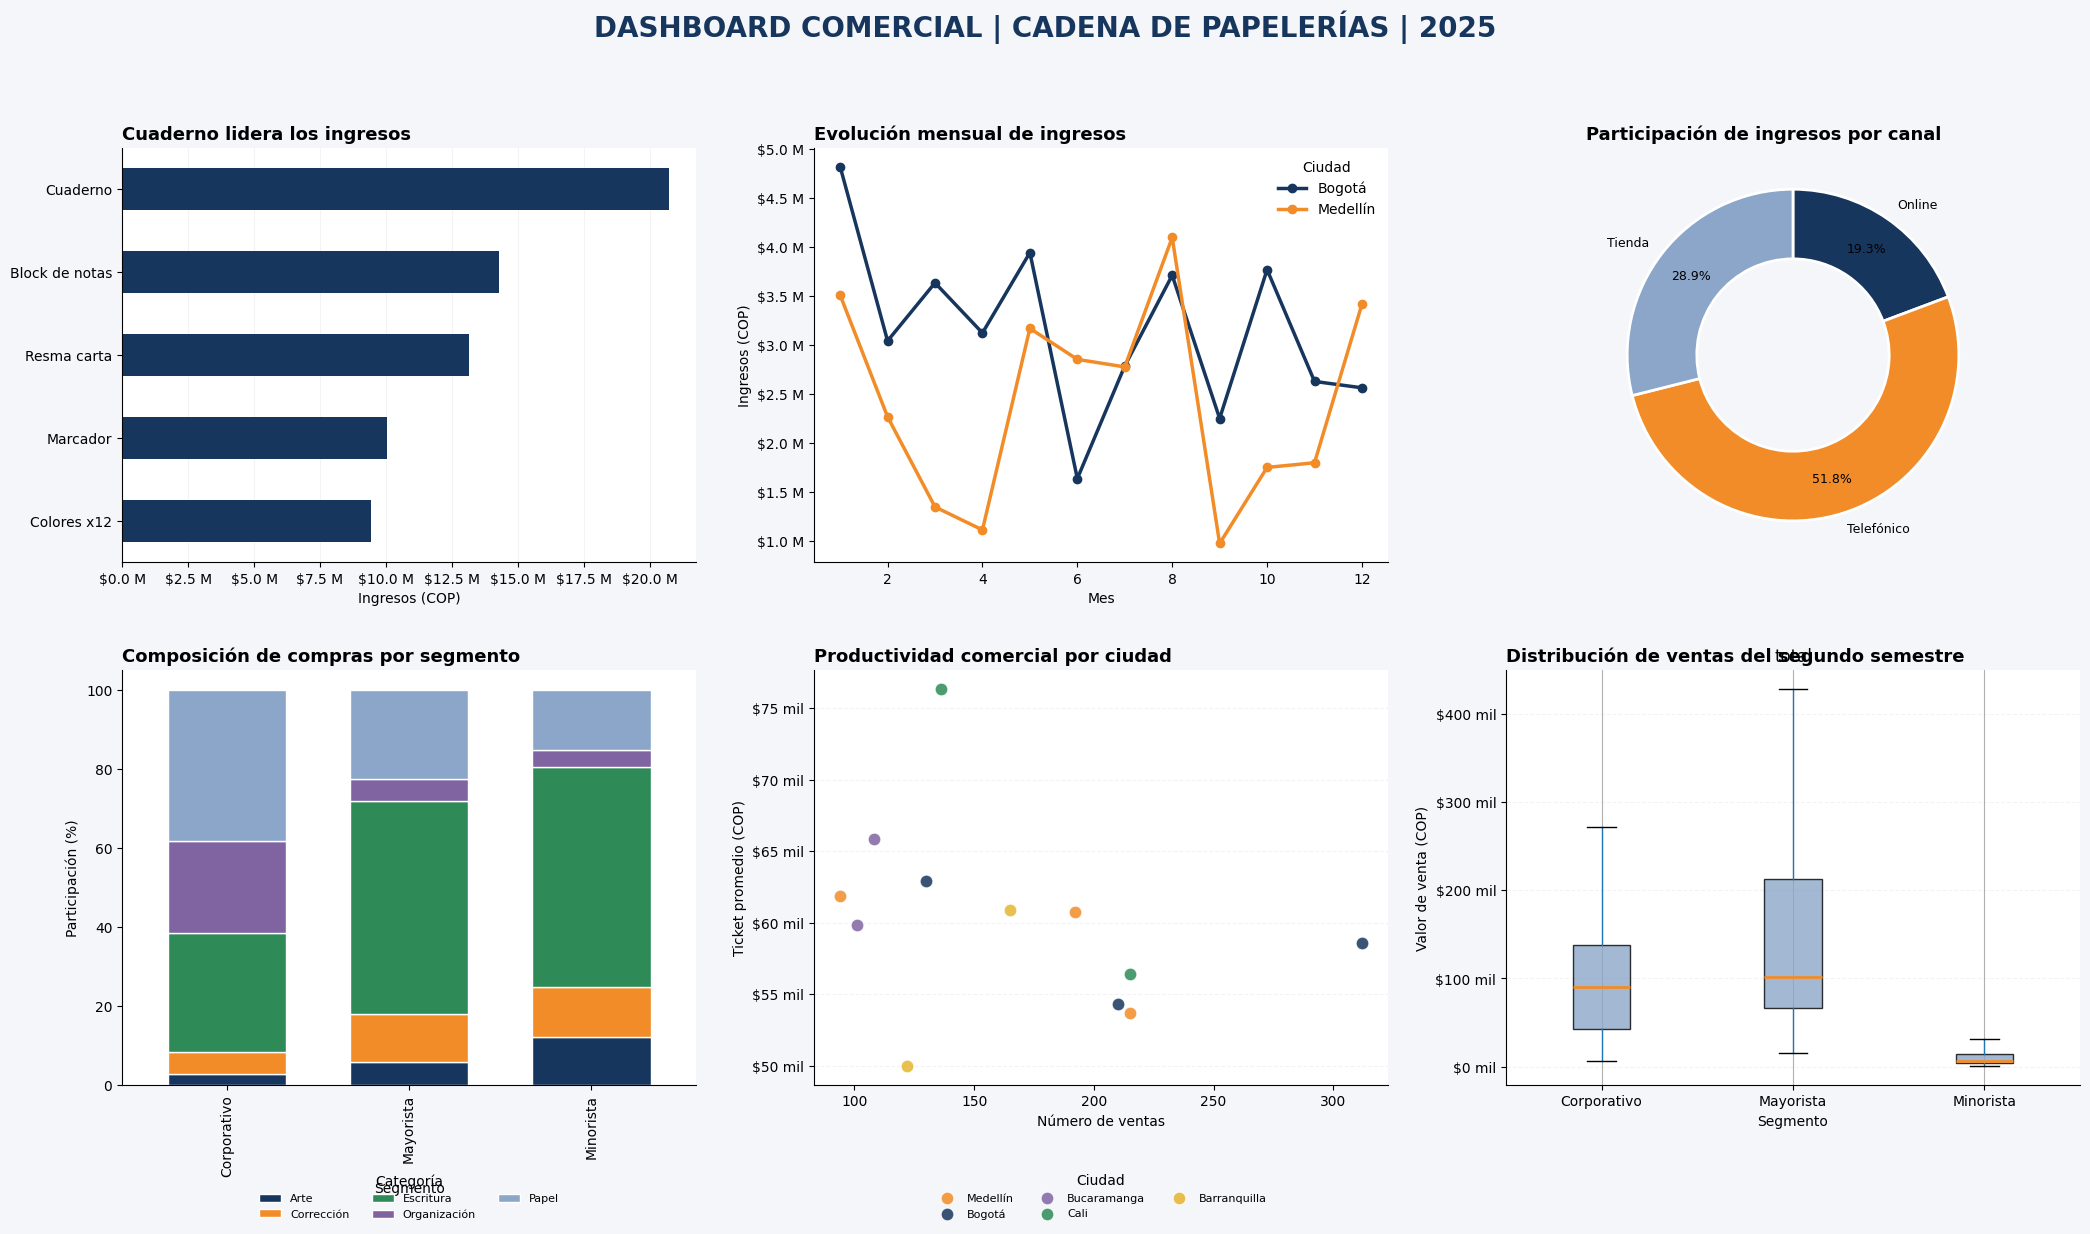

In [ ]:
mostrar("v2")

### Ejercicio 10 *(opcional)* · Una tercera versión
Si quieres seguir mejorando, crea `prompt_v3` (parte de `prompt_v2`), repite el ciclo con `figura_v3.py` y muestra `mostrar("v3")`.

In [ ]:

prompt_v3 = prompt_v2 + """

AJUSTES FINALES:
1. Elimina cualquier superposición de títulos en el
diagrama de cajas. Construye el boxplot directamente
con matplotlib para evitar títulos automáticos.

2. Ubica las leyendas de los gráficos 4 y 5 dentro
de sus paneles, en posiciones que no tapen los datos.

3. Aumenta la altura de la figura y mejora los márgenes
para que los títulos, etiquetas y leyendas no se crucen.

4. En el gráfico de dona, coloca en el centro el nombre
del canal con mayor participación y su porcentaje real.

5. Conserva la paleta azul marino, naranja, verde,
violeta y azul claro. Mantén una identidad corporativa.

REGLAS:
Conserva exactamente los seis gráficos, los datos,
las variables y los resultados de las versiones anteriores.
No cambies cálculos ni inventes cifras.
La figura debe llamarse fig y tener 2 filas y 3 columnas.
No uses plt.show() ni guardes archivos.
Entrega el código completo de Python.
"""

print(prompt_v3)



AJUSTES SOBRE LA VERSIÓN 1:

1. Cambia el gráfico circular de ingresos por canal
por un gráfico de dona, conservando los porcentajes
originales y destacando el 51.8% del canal telefónico.

2. Reubica la leyenda del gráfico de categorías para
que no tape las barras apiladas.

3. Mejora la leyenda del gráfico de dispersión,
utilizando una distribución compacta y ordenada.

4. Corrige la superposición del título automático
del diagrama de cajas con su título principal.

5. Aumenta ligeramente los espacios entre los seis
paneles para mejorar la lectura.

CONSERVACIÓN:
Mantén exactamente los mismos seis gráficos,
los mismos datos, las mismas tablas y los mismos
cálculos de la versión original.
Conserva la cuadrícula de dos filas y tres columnas,
la variable fig y los nombres de las variables.
No inventes cifras ni modifiques los resultados.

ESTILO:
Mantén la identidad corporativa azul marino,
blanco y naranja. Conserva una apariencia limpia,
elegante y profesional.


AJUSTES FINALES:
1. E

In [ ]:

%%writefile figura_v3.py

from matplotlib.ticker import FuncFormatter

# Paleta corporativa
colores_ciudad = {
    "Bogotá": "#17365D",
    "Medellín": "#F28C28",
    "Cali": "#2E8B57",
    "Barranquilla": "#E5B52F",
    "Bucaramanga": "#8064A2"
}

fig, axs = plt.subplots(2, 3, figsize=(22, 14))
fig.patch.set_facecolor("#F4F6FA")

for ax in axs.flat:
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.15, linestyle="--")
    ax.set_axisbelow(True)

# 1. Top 5 productos
top_productos.sort_values().plot.barh(
    ax=axs[0, 0],
    color="#17365D",
    edgecolor="white"
)
axs[0, 0].set_title(
    "Top 5 productos por ingresos",
    fontsize=13, fontweight="bold", loc="left"
)
axs[0, 0].set_xlabel("Ingresos (COP)")
axs[0, 0].set_ylabel("")
axs[0, 0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, p: f"${x/1e6:.1f} M")
)
axs[0, 0].grid(axis="x", alpha=0.15)
axs[0, 0].grid(axis="y", visible=False)

# 2. Evolución mensual Bogotá y Medellín
ing_mes_ciudad.plot.line(
    ax=axs[0, 1],
    marker="o",
    linewidth=2.5,
    markersize=6,
    color=["#17365D", "#F28C28"]
)
axs[0, 1].set_title(
    "Evolución mensual: Bogotá vs Medellín",
    fontsize=13, fontweight="bold", loc="left"
)
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos (COP)")
axs[0, 1].yaxis.set_major_formatter(
    FuncFormatter(lambda x, p: f"${x/1e6:.1f} M")
)
axs[0, 1].legend(frameon=False, fontsize=9)
axs[0, 1].grid(axis="y", alpha=0.15)

# 3. Participación por canal: gráfico de dona
ing_canal.plot.pie(
    ax=axs[0, 2],
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    colors=["#17365D", "#F28C28", "#8BA6C9"],
    wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2},
    pctdistance=0.78,
    textprops={"fontsize": 9}
)

canal_lider = ing_canal.idxmax()
porcentaje_lider = ing_canal.max() / ing_canal.sum() * 100

axs[0, 2].text(
    0, 0,
    f"{canal_lider}\n{porcentaje_lider:.1f}%",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold",
    color="#17365D"
)
axs[0, 2].set_title(
    "Participación de ingresos por canal",
    fontsize=13, fontweight="bold", loc="left"
)
axs[0, 2].set_ylabel("")

# 4. Compras por segmento y categoría
tabla_seg_cat.plot.bar(
    ax=axs[1, 0],
    stacked=True,
    color=["#17365D", "#F28C28", "#2E8B57", "#8064A2", "#8BA6C9"],
    edgecolor="white",
    width=0.65
)
axs[1, 0].set_title(
    "Composición de compras por segmento",
    fontsize=13, fontweight="bold", loc="left"
)
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Participación (%)")
axs[1, 0].legend(
    title="Categoría",
    frameon=True,
    framealpha=0.9,
    fontsize=8,
    loc="upper left",
    ncol=2
)

# 5. Productividad de vendedores
for ciudad in vend["ciudad"].unique():
    datos = vend[vend["ciudad"] == ciudad]
    axs[1, 1].scatter(
        datos["n_ventas"],
        datos["ticket_prom"],
        label=ciudad,
        color=colores_ciudad[ciudad],
        s=85,
        alpha=0.85,
        edgecolors="white",
        linewidths=0.8
    )

axs[1, 1].set_title(
    "Productividad comercial por ciudad",
    fontsize=13, fontweight="bold", loc="left"
)
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket promedio (COP)")
axs[1, 1].yaxis.set_major_formatter(
    FuncFormatter(lambda x, p: f"${x/1000:.0f} mil")
)
axs[1, 1].legend(
    title="Ciudad",
    frameon=True,
    framealpha=0.9,
    fontsize=8,
    loc="upper right",
    ncol=2
)

# 6. Diagrama de cajas sin títulos automáticos
orden_segmentos = ["Corporativo", "Mayorista", "Minorista"]

datos_boxplot = [
    sem2.loc[sem2["segmento"] == segmento, "total"].values
    for segmento in orden_segmentos
]

bp = axs[1, 2].boxplot(
    datos_boxplot,
    labels=orden_segmentos,
    showfliers=False,
    patch_artist=True,
    medianprops={"color": "#F28C28", "linewidth": 2},
    whiskerprops={"color": "#17365D"},
    capprops={"color": "#17365D"}
)

for caja in bp["boxes"]:
    caja.set_facecolor("#8BA6C9")
    caja.set_alpha(0.85)

axs[1, 2].set_title(
    "Distribución de ventas del segundo semestre",
    fontsize=13, fontweight="bold", loc="left"
)
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Valor de venta (COP)")
axs[1, 2].yaxis.set_major_formatter(
    FuncFormatter(lambda x, p: f"${x/1000:.0f} mil")
)

# Título y distribución general
fig.suptitle(
    "DASHBOARD COMERCIAL | CADENA DE PAPELERÍAS | 2025",
    fontsize=20,
    fontweight="bold",
    color="#17365D",
    y=0.98
)

plt.tight_layout(
    rect=[0.02, 0.03, 0.98, 0.94],
    h_pad=3,
    w_pad=2
)


Overwriting figura_v3.py


<string>:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.


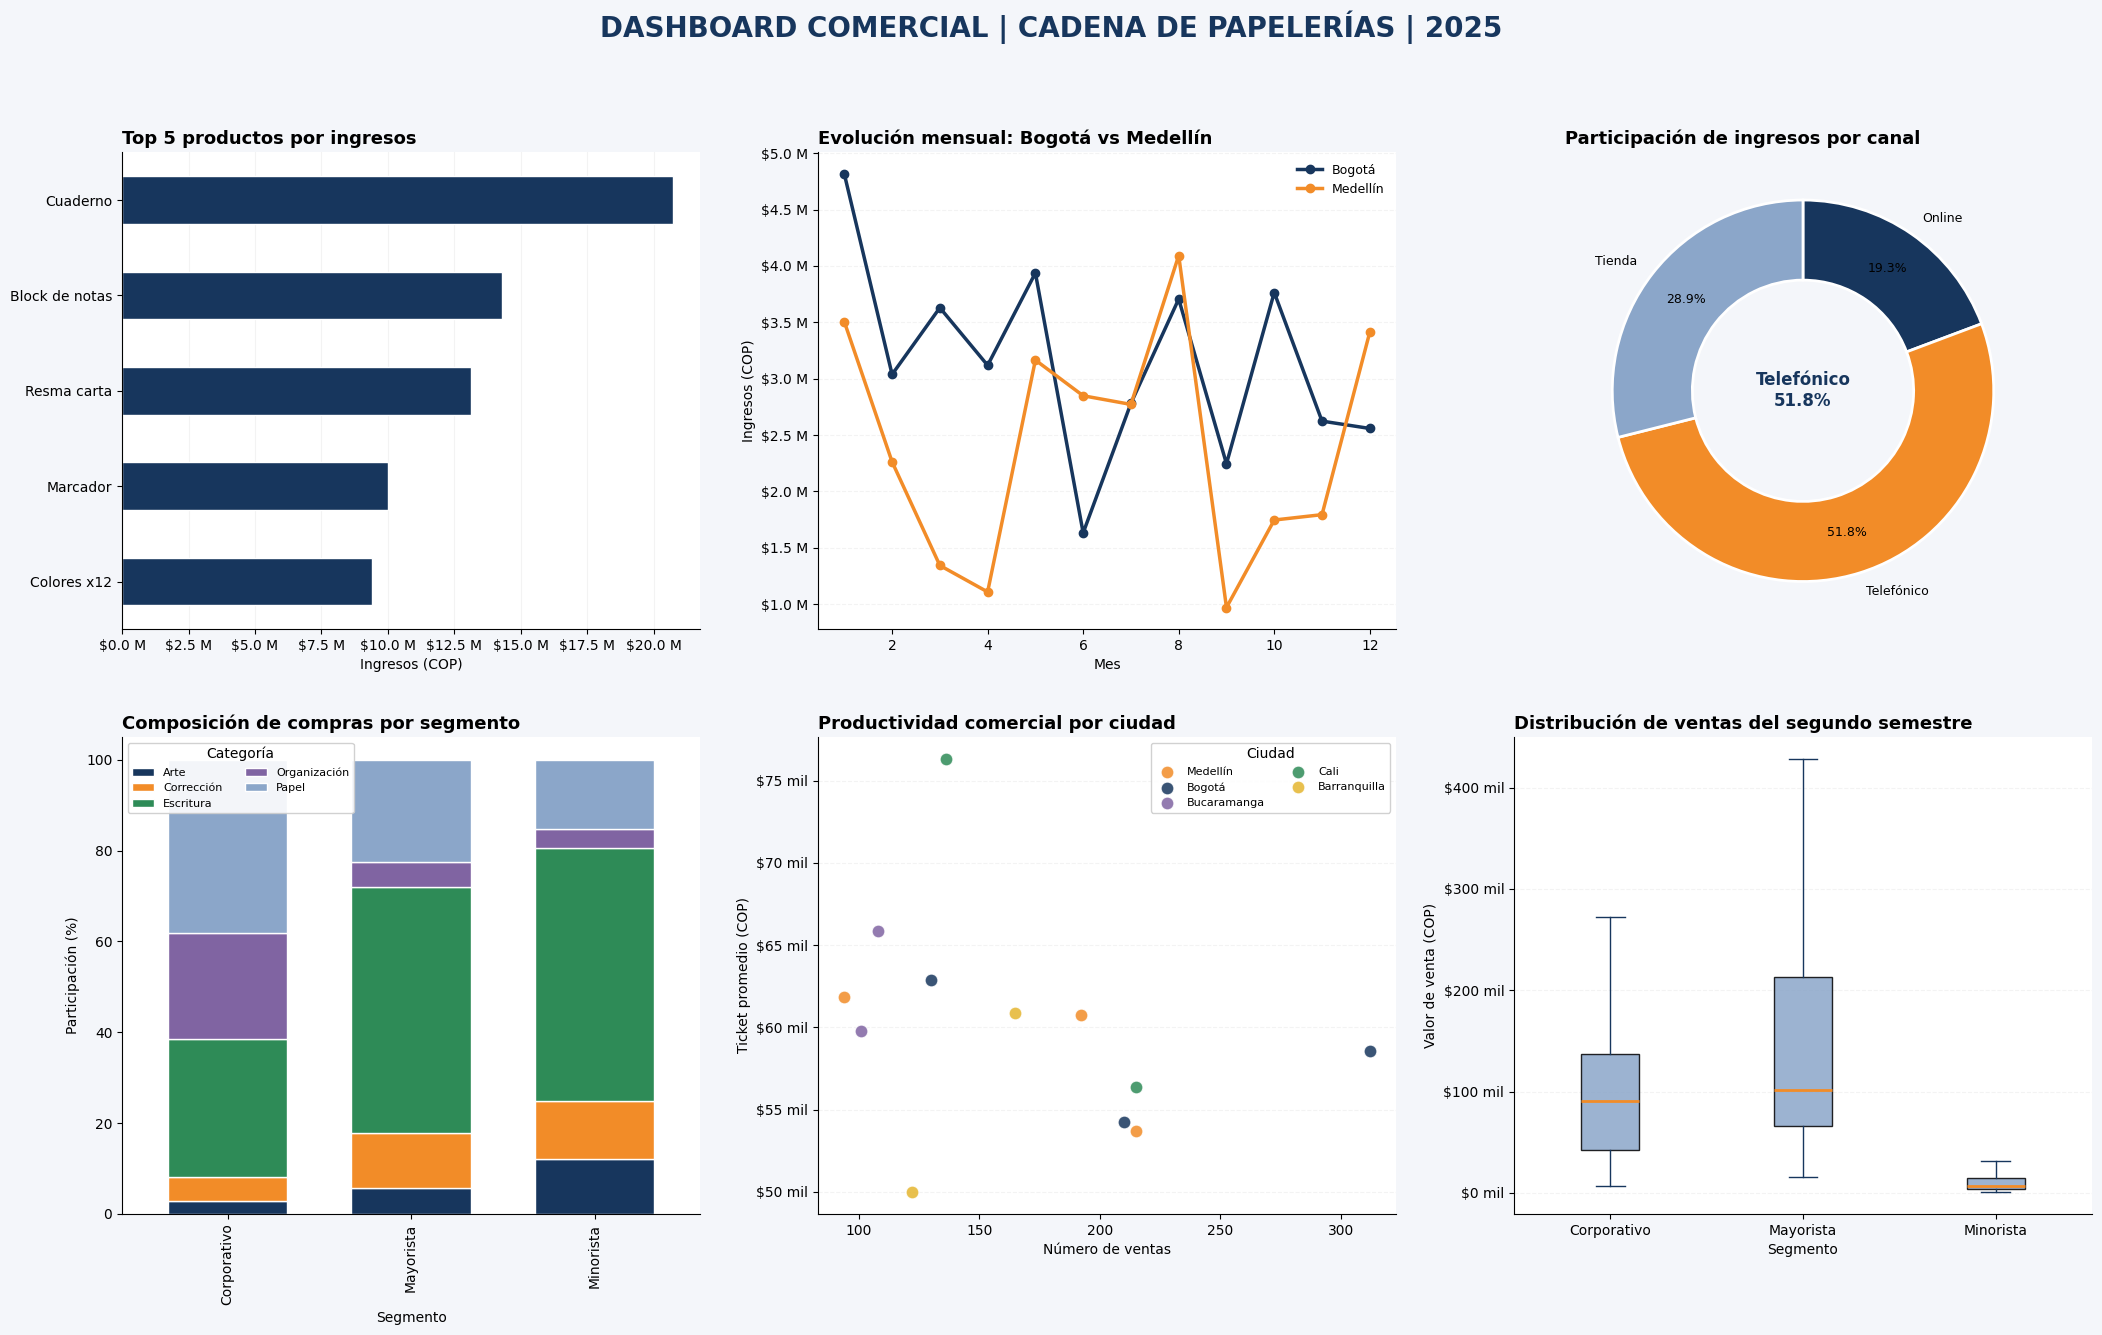

In [ ]:
mostrar("v3")

---
# Parte D · Elige tu favorita y publícala
### Ejercicio 11 · Tu dashboard final y tus conclusiones
Mira tus versiones y **elige la que más te guste**. Luego escribe **3 hallazgos**: frases cortas con **cifras reales** sacadas de tus tablas. Se mostrarán debajo de tu dashboard.

*Ejemplo de hallazgo:* "Bogotá genera el 32 % de los ingresos de la cadena."

In [ ]:
figura_elegida = "v3"      # cambia por "v1", "v2" o "v3"

hallazgos = [
    "Bogotá es la ciudad con mayor participación en los ingresos de la cadena, generando $37.847.614, equivalentes al 31,89 % de la facturación total",
    "El canal telefónico representa el 51,78 % de los ingresos, con $61.450.716, lo que evidencia su importancia dentro de la operación comercial.",
    "El segmento mayorista concentra el 52,33 % de los ingresos, con $62.102.018, posicionándose como el segmento de clientes más importante en términos de facturación.",
]


In [ ]:
# ✅ Verificación
import os
assert os.path.exists(f"figura_{figura_elegida}.py"), f"No existe figura_{figura_elegida}.py: revisa figura_elegida"
assert len(hallazgos) == 3 and all(len(h) > 25 and "ESCRIBE AQUÍ" not in h for h in hallazgos), "Escribe tus 3 hallazgos con cifras"
print("Ejercicio 11 correcto ✔")

Ejercicio 11 correcto ✔


### Tu dashboard final
Ejecuta la celda: muestra la versión que elegiste y tus tres hallazgos. **Esta es la salida que se verá en GitHub.**

<string>:154: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.


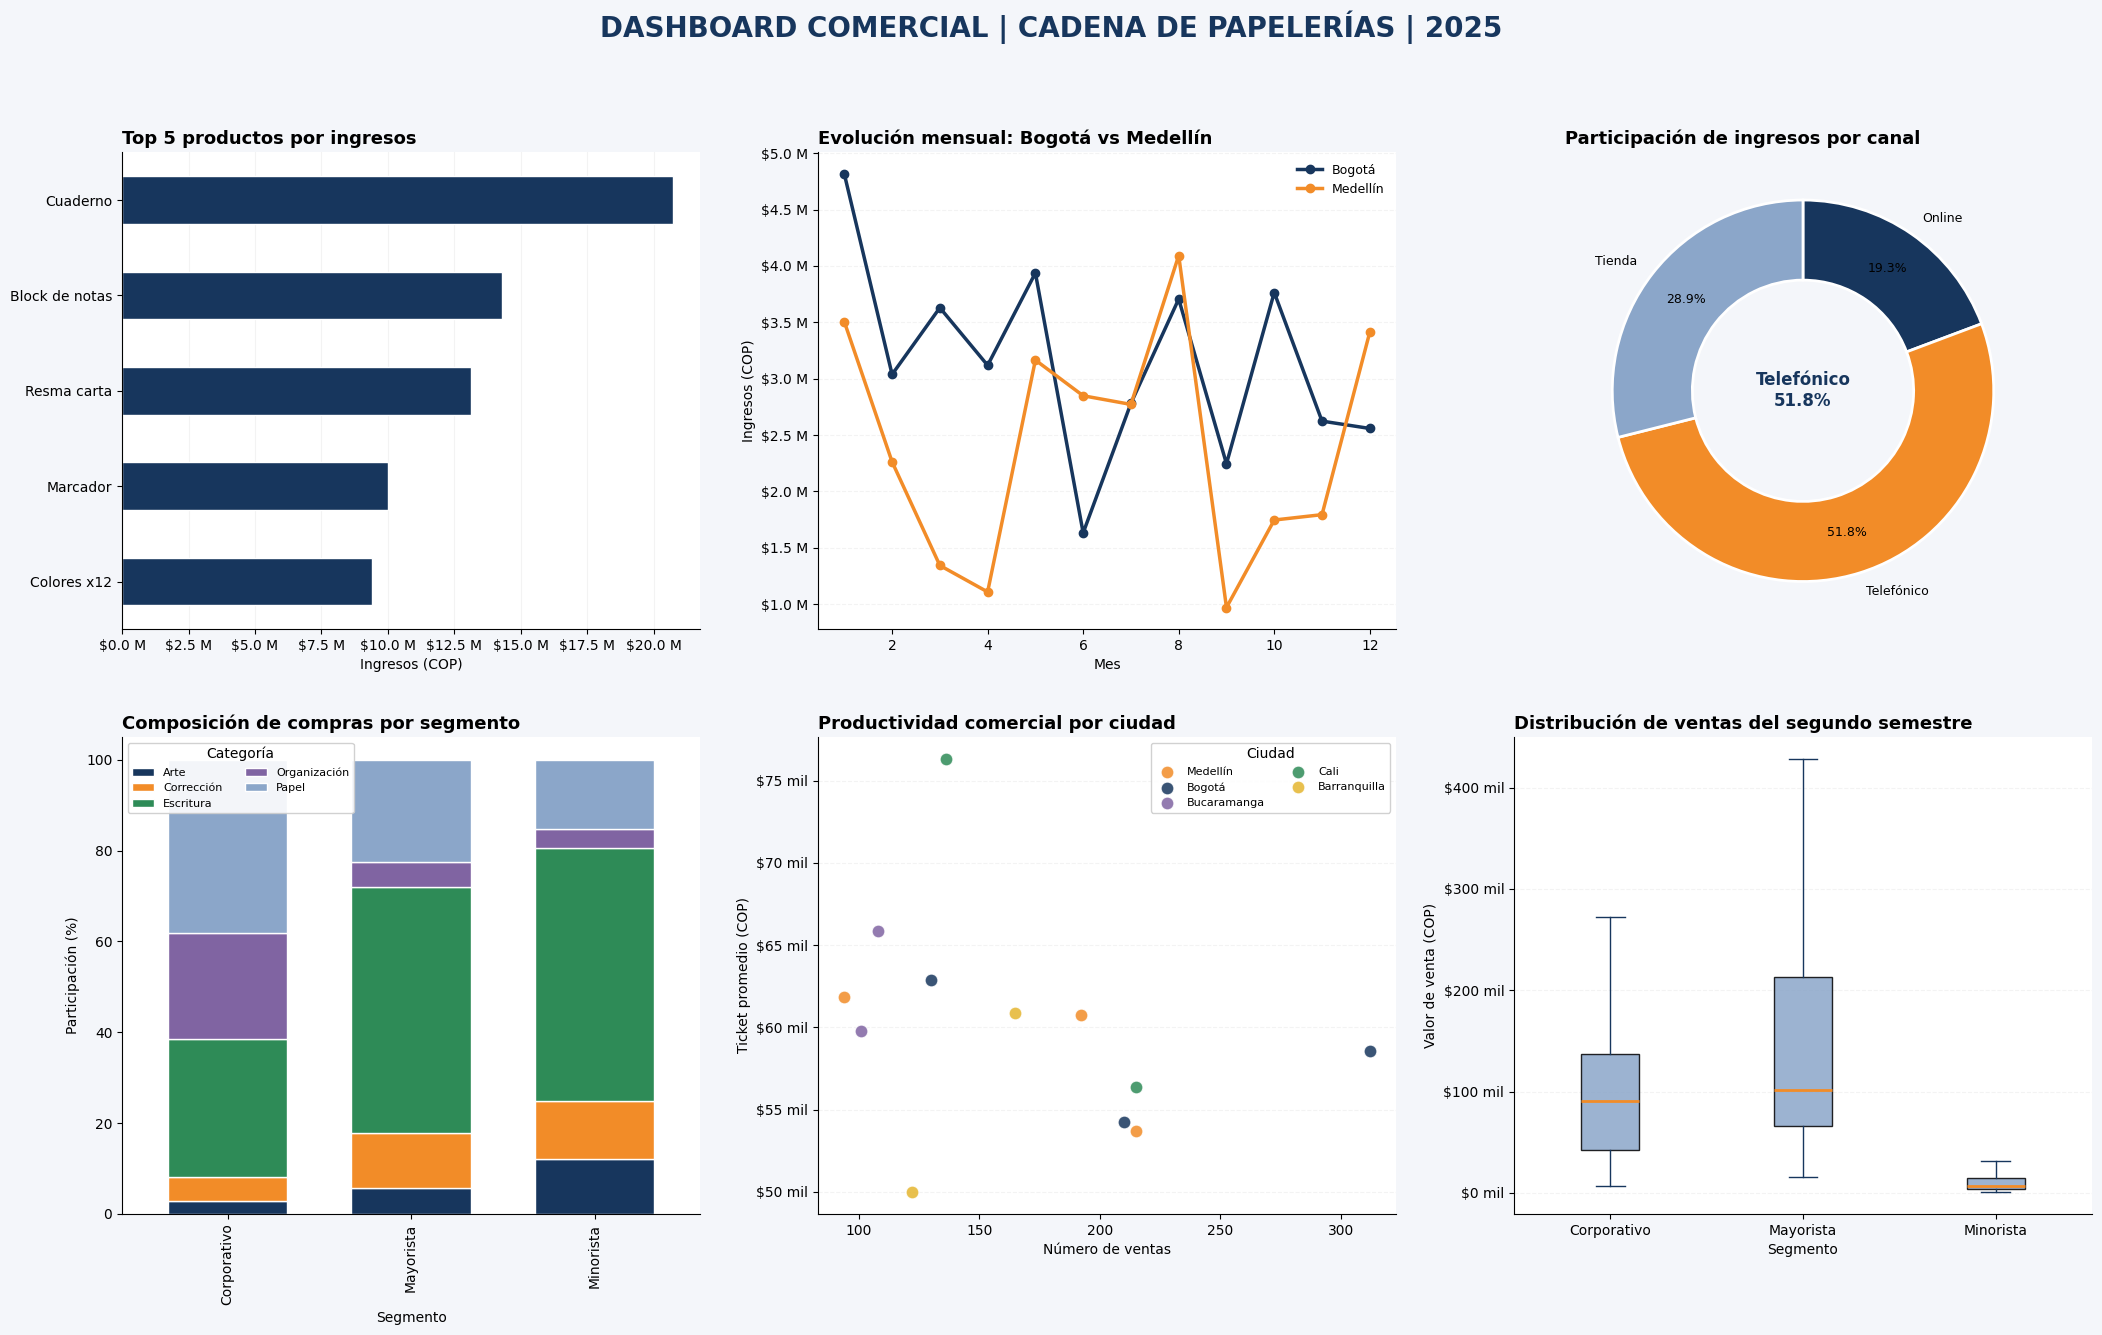

Hallazgos:
• Bogotá es la ciudad con mayor participación en los ingresos de la cadena, generando $37.847.614, equivalentes al 31,89 % de la facturación total
• El canal telefónico representa el 51,78 % de los ingresos, con $61.450.716, lo que evidencia su importancia dentro de la operación comercial.
• El segmento mayorista concentra el 52,33 % de los ingresos, con $62.102.018, posicionándose como el segmento de clientes más importante en términos de facturación.


In [ ]:
mostrar(figura_elegida)

print("Hallazgos:")
for h in hallazgos:
    print("•", h)

### Ejercicio 12 · Publica tu notebook en GitHub
GitHub muestra los notebooks **con sus figuras**, así que tu notebook publicado es tu dashboard. Solo necesitas una cuenta gratuita en [github.com](https://github.com).

**Antes de publicar:**
- Ejecuta todo el notebook de arriba abajo (*Entorno de ejecución → Ejecutar todo*) para que las figuras queden guardadas en las salidas.
- **Nunca escribas tu API key dentro de una celda.** Los *Secrets* de Colab no se guardan en el notebook y por eso son seguros; el repositorio será público.

**Pasos:**
1. **Crea el repositorio:** botón **New** → nombre `mi-dashboard-ventas` → **Public** → *Create repository*.
2. **Guarda el notebook en GitHub.** Opción A: en Colab, *Archivo → Guardar una copia en GitHub*, autoriza, elige tu repositorio y acepta. Opción B: *Archivo → Descargar → .ipynb* y, en el repositorio, **Add file → Upload files** y arrastra el archivo.
3. **Abre el notebook en el repositorio** (haz clic en el archivo `.ipynb`): GitHub lo dibuja con tus figuras.
4. **Copia el enlace** de la barra del navegador. Debe verse así: `https://github.com/TU-USUARIO/mi-dashboard-ventas/blob/main/NOMBRE.ipynb`
5. **Compruébalo:** ábrelo en una ventana de incógnito. Si lo ves sin iniciar sesión, está público.

**Si no se ven las figuras:** vuelve a Colab, ejecuta todo y guarda de nuevo. Si GitHub dice *Unable to render code block*, recarga la página unos segundos después.

---
**Para entregar:** (1) el **enlace público** de tu notebook en GitHub, con tu dashboard final visible, todos los integrantes deben estar como colaboradores en el repositorio, y (2) tus prompts (`prompt_v1`, `prompt_v2` y, si la hiciste, `prompt_v3`) más **tres líneas** sobre qué tuviste que corregir de lo que hizo Gemini y cómo lo pediste (escríbelas en una celda de texto al final del notebook) (3) El notebook (ipynb) con los nombres de todos los integrantes.